In [ ]:
#1 Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving X_test_clean.csv to X_test_clean.csv
Saving X_train_clean.csv to X_train_clean.csv
Saving y_test_clean.csv to y_test_clean.csv
Saving y_train_clean.csv to y_train_clean.csv


In [ ]:
#2 Loading the leakage-free, pre-split, pre-imputed data
X_train = pd.read_csv("X_train_clean.csv")
X_test = pd.read_csv("X_test_clean.csv")
y_train = pd.read_csv("y_train_clean.csv").squeeze()
y_test = pd.read_csv("y_test_clean.csv").squeeze()

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (614, 8)
Test shape : (154, 8)


In [ ]:
#3 Building the SMOTE + Random Forest pipeline
rf_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
])

In [ ]:
#4 Defining the hyperparameter search space
param_dist = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
    "clf__bootstrap": [True, False]
}

In [ ]:
#5 Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [ ]:
#6 Running RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=50,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random_search.fit(X_train, y_train)

print("Best Parameters:", rf_random_search.best_params_)
print("Best CV ROC-AUC:", rf_random_search.best_score_)

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 5, 'clf__bootstrap': True}
Best CV ROC-AUC: 0.8326298701298702


In [ ]:
#7 Evaluating the tuned Random Forest on the test set
best_rf_model = rf_random_search.best_estimator_

y_pred_rf = best_rf_model.predict(X_test)
y_prob_rf = best_rf_model.predict_proba(X_test)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("="*50)
print("TUNED RANDOM FOREST RESULTS")
print("="*50)
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC AUC  : {roc_auc_rf:.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

TUNED RANDOM FOREST RESULTS
Accuracy : 0.7273
Precision: 0.5882
Recall   : 0.7407
F1 Score : 0.6557
ROC AUC  : 0.8222

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.72      0.77       100
           1       0.59      0.74      0.66        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73      0.73       154


Confusion Matrix
[[72 28]
 [14 40]]


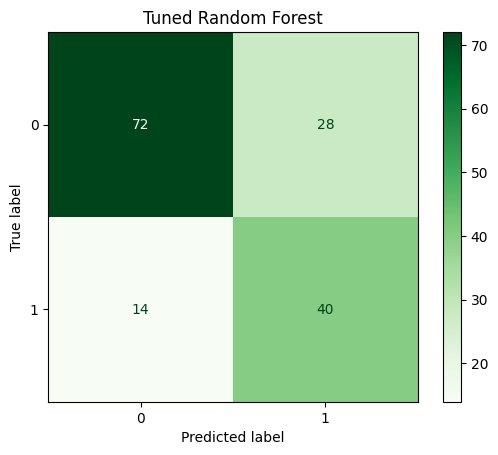

In [ ]:
#8 Plotting Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    cmap="Greens"
)
plt.title("Tuned Random Forest")
plt.show()

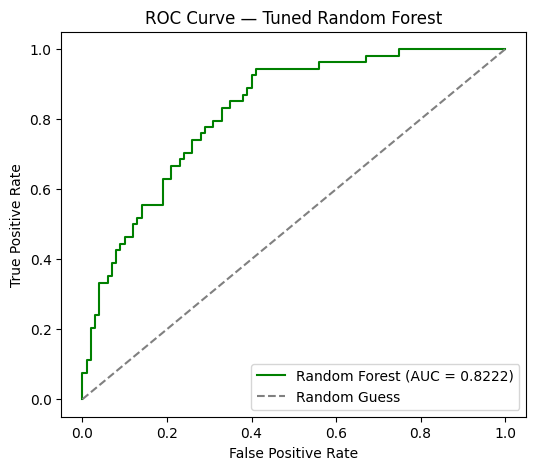

In [ ]:
#9 Plotting ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(6, 5))
plt.plot(fpr_rf, tpr_rf, color="green", label=f"Random Forest (AUC = {roc_auc_rf:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Tuned Random Forest")
plt.legend(loc="lower right")
plt.show()

In [ ]:
#10 Feature Importance
feat_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.named_steps["clf"].feature_importances_
}).sort_values(by="Importance", ascending=False)

print(feat_importance_df)

                    Feature  Importance
1                   Glucose    0.290651
4                   Insulin    0.209980
5                       BMI    0.155163
7                       Age    0.109325
3             SkinThickness    0.083755
6  DiabetesPedigreeFunction    0.059463
0               Pregnancies    0.051840
2             BloodPressure    0.039824


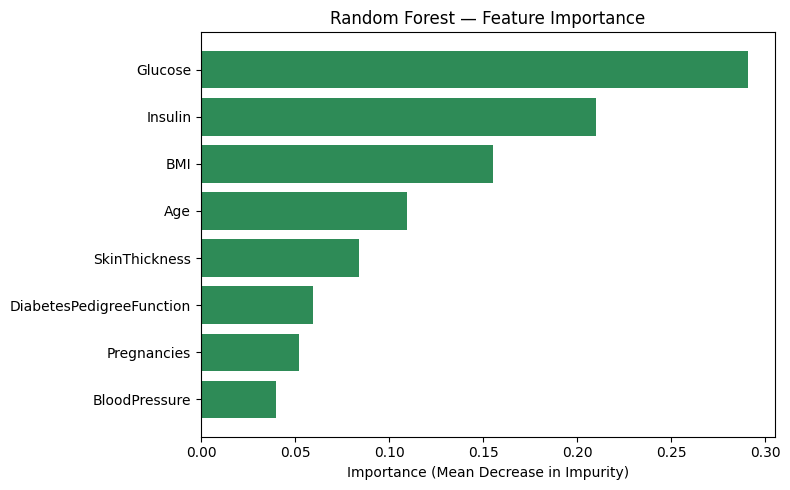

In [ ]:
#11 Plotting Feature Importance
plt.figure(figsize=(8, 5))
plt.barh(feat_importance_df["Feature"], feat_importance_df["Importance"], color="seagreen")
plt.gca().invert_yaxis()
plt.xlabel("Importance (Mean Decrease in Impurity)")
plt.title("Random Forest — Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
#12 Model Comparison Table (tuned LR vs tuned RF)
comparison_df = pd.DataFrame({
    "Logistic Regression": [0.7143, 0.5806, 0.6667, 0.6207, 0.8089],
    "Random Forest": [accuracy_rf, precision_rf, recall_rf, f1_rf, roc_auc_rf]
}, index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])

print(comparison_df.round(4))

           Logistic Regression  Random Forest
Accuracy                0.7143         0.7273
Precision               0.5806         0.5882
Recall                  0.6667         0.7407
F1-Score                0.6207         0.6557
ROC-AUC                 0.8089         0.8222


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Capstone', 'Play Books Notes', 'Naledi-klasnotas-graad-12-2018.pdf', 'Motivation.docx', 'T4_GraphsofTrigFunction_BP_9_22_14.pdf', 'MATHS-FUNCTIONS.pdf', '202455031_Kudzanai_Tauzeni.pdf', 'Colab Notebooks', 'K_Tauzeni_ NSC.pdf', 'K_Tauzeni ID.pdf', 'Father_Affidavit.pdf', 'Mother_Affidavit.pdf']


In [ ]:
print(os.listdir("/content/drive/MyDrive/Capstone"))

['04_Random_Forest.ipynb', 'X_train_clean.csv', 'y_train_clean.csv', 'y_test_clean.csv', 'X_test_clean.csv', '05_XGBoost.ipynb', 'models', '03_Logistic_Regression (1).ipynb']


In [ ]:
import joblib

joblib.dump(
    best_rf_model,
    "/content/drive/MyDrive/Capstone/models/random_forest_pipeline.pkl"
)

['/content/drive/MyDrive/Capstone/models/random_forest_pipeline.pkl']